# Módulo 1: ¿Qué tan bien predice un Elo simple los partidos de la NBA?

**Pregunta:** ¿cuánto mejora un rating Elo a dos baselines tontos (moneda y "gana el local"), medido con log loss, Brier y calibración, y con validación estrictamente temporal?

**Diseño (decidido antes de ver resultados):**
- Calentamiento de ratings: 2015-16 a 2022-23.
- Elección de parámetros (K, ventaja de local, regresión a la media): **solo** con 2023-24 y 2024-25.
- Prueba final: 2025-26, que se evalúa una vez al final.

**Mi hipótesis previa:** ninguna ("mi intuición es X"). Comparo contra baselines, no contra una intuición.

Para reproducir: `python -m uv run jupyter lab` desde la raíz del repo. Los datos salen de la caché local, así que no vuelve a pedir nada a NBA.com.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from sportslab.data import NbaClient
from sportslab.data.games import load_games, season_labels
from sportslab.models.experiment import home_rate_by_season, run_elo_experiment

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

VALIDATION = ["2023-24", "2024-25"]
TEST = "2025-26"

games = load_games(NbaClient(), season_labels(2015, 2025))
print(
    f"{len(games)} partidos, {games['neutral_site'].sum()} en sede neutral (sin ventaja de local)"
)

13209 partidos, 10 en sede neutral (sin ventaja de local)


## 1. La ventaja de local no es constante

El Elo clásico suma ~100 puntos al local. Antes de usar ese número, miro qué dicen los datos.

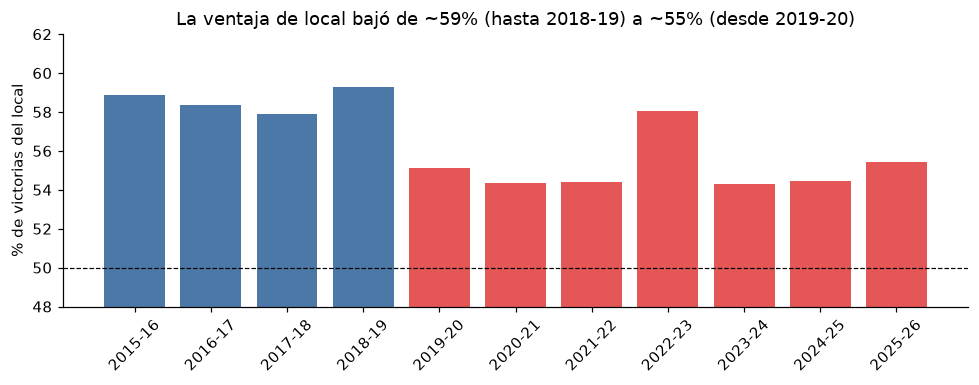

In [2]:
rate = home_rate_by_season(games)
early, late = rate.loc[:"2018-19"].mean(), rate.loc["2019-20":].mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(
    rate.index,
    rate.values * 100,
    color=["#4C78A8" if s <= "2018-19" else "#E45756" for s in rate.index],
)
ax.axhline(50, color="k", lw=0.8, ls="--")
ax.set_ylim(48, 62)
ax.set_ylabel("% de victorias del local")
ax.set_title(
    f"La ventaja de local bajó de ~{early:.0%} (hasta 2018-19) a ~{late:.0%} (desde 2019-20)"
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Nota de muestra:** cada temporada tiene ~1225 partidos; el error estándar de una tasa de ~55 % es ≈ 1.4 puntos. Desde 2019-20, 6 de las 7 temporadas quedan en 54-55 %; la excepción es 2022-23 (58 %), así que la caída no es perfectamente limpia. Un salto de ~4 puntos entre promedios es difícil de atribuir solo al azar, pero el gráfico no explica *por qué* (¿COVID, viajes, arbitraje?). Eso es una pregunta, no una conclusión.

## 2. El modelo

```
P(local gana) = 1 / (1 + 10^(-(R_local + H - R_visita) / 400))
R_nuevo = R_viejo + K · (resultado - P_esperada)
al cambiar de temporada: R = 1500 + carryover · (R - 1500)
```

Cada predicción se hace **antes** de aplicar el resultado de ese partido (hay un test que lo comprueba).

## 3. Elección de parámetros (solo validación)

Parámetros elegidos en validación: EloParams(k=24.0, home_advantage=40.0, carryover=0.7, initial=1500.0)


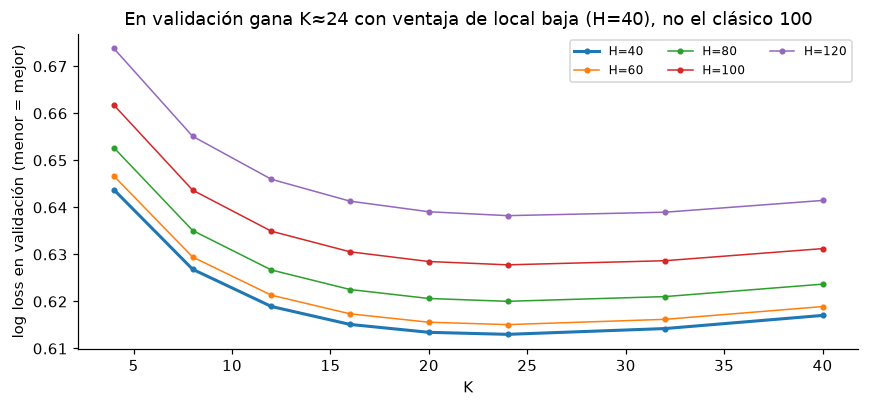

 k  home_advantage  carryover  log_loss
24              40       0.70    0.6130
24              40       0.60    0.6131
24              40       0.75    0.6131
24              40       0.80    0.6134
20              40       0.70    0.6134


In [3]:
exp = run_elo_experiment(games, validation=VALIDATION, test=TEST)
best = exp.tuned
print("Parámetros elegidos en validación:", best)

at_best_c = exp.grid[exp.grid["carryover"] == best.carryover]
curves = at_best_c.pivot(index="k", columns="home_advantage", values="log_loss")

fig, ax = plt.subplots(figsize=(8, 3.8))
for h in curves.columns:
    ax.plot(
        curves.index,
        curves[h],
        marker="o",
        ms=3,
        label=f"H={h:.0f}",
        lw=2 if h == best.home_advantage else 1,
    )
ax.set_xlabel("K")
ax.set_ylabel("log loss en validación (menor = mejor)")
ax.set_title(
    f"En validación gana K≈{best.k:.0f} con ventaja de local baja (H={best.home_advantage:.0f}), no el clásico 100"
)
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()
print(exp.grid.head(5).round(4).to_string(index=False))

**Dos advertencias honestas:**
1. El mejor H cae en el **borde** de la rejilla (40 es el valor más bajo probado). El óptimo real puede ser menor; la rejilla debió incluir 0 y 20. Es el ejercicio de este módulo.
2. La curva en K es plana cerca del mínimo (K de 20 a 24 casi no cambia el log loss): no hay un K "mágico", hay una zona razonable.

## 4. Resultado en la temporada de prueba (2025-26)

In [4]:
scores = exp.scores.round(4)
scores

,log_loss,brier,accuracy
coin 50%,0.6931,0.2500,0.5000
home rate (train),0.6875,0.2472,0.5543
elo default,0.6171,0.2133,0.6661
elo tuned,0.6037,0.2080,0.6808


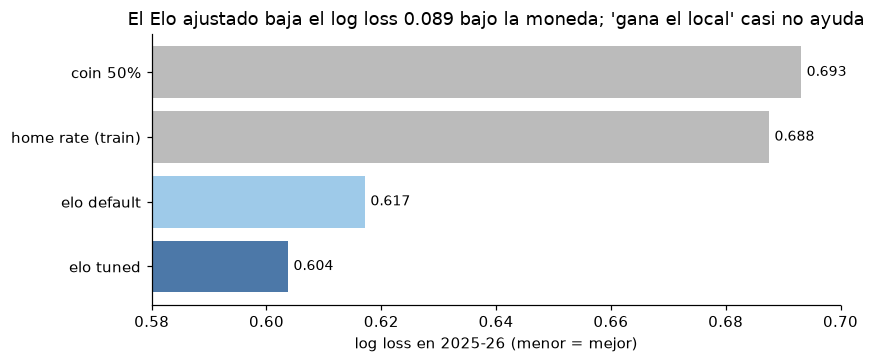

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
colors = ["#BBBBBB", "#BBBBBB", "#9ECAE9", "#4C78A8"]
ax.barh(scores.index[::-1], scores["log_loss"][::-1], color=colors[::-1])
ax.set_xlim(0.58, 0.70)
for y, v in enumerate(scores["log_loss"][::-1]):
    ax.text(v + 0.001, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("log loss en 2025-26 (menor = mejor)")
gain = scores.loc["coin 50%", "log_loss"] - scores.loc["elo tuned", "log_loss"]
ax.set_title(
    f"El Elo ajustado baja el log loss {gain:.3f} bajo la moneda; 'gana el local' casi no ayuda"
)
plt.tight_layout()
plt.show()

**Cómo leerlo:** el log loss de la moneda es ln 2 = 0.693. Un log loss de 0.60 equivale a asignar en promedio ~55 % de probabilidad al resultado que ocurrió; en deportes no se baja de eso de forma realista porque hay mucho azar. La precisión (acierto del favorito) es secundaria: no dice qué tan seguro estabas.

## 5. Calibración: ¿el 70 % que dice el modelo gana el 70 %?

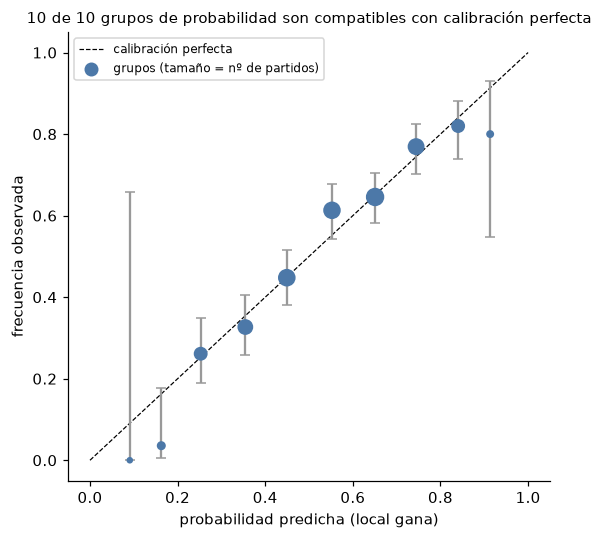

 bin   n  mean_pred  observed  ci_low  ci_high
   0   2      0.091     0.000   0.000    0.658
   1  28      0.163     0.036   0.006    0.177
   2 111      0.253     0.261   0.189    0.350
   3 153      0.355     0.327   0.258    0.405
   4 201      0.449     0.448   0.381    0.517
   5 199      0.552     0.613   0.544    0.678
   6 223      0.651     0.646   0.581    0.706
   7 182      0.744     0.769   0.703    0.824
   8 111      0.840     0.820   0.738    0.880
   9  15      0.913     0.800   0.548    0.930


In [6]:
cal = exp.calibration
inside = ((cal["mean_pred"] >= cal["ci_low"]) & (cal["mean_pred"] <= cal["ci_high"])).sum()

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="calibración perfecta")
ax.errorbar(
    cal["mean_pred"],
    cal["observed"],
    yerr=[cal["observed"] - cal["ci_low"], cal["ci_high"] - cal["observed"]],
    fmt="none",
    ecolor="#999999",
    capsize=3,
)
ax.scatter(
    cal["mean_pred"],
    cal["observed"],
    s=cal["n"] / 2 + 10,
    color="#4C78A8",
    zorder=3,
    label="grupos (tamaño = nº de partidos)",
)
ax.set_xlabel("probabilidad predicha (local gana)")
ax.set_ylabel("frecuencia observada")
ax.set_title(
    f"{inside} de {len(cal)} grupos de probabilidad son compatibles con calibración perfecta",
    fontsize=10,
)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
print(cal.round(3).to_string(index=False))

**Tamaño de muestra:** los grupos extremos tienen muy pocos partidos (barras de error enormes). Un desvío ahí es ruido hasta que se demuestre lo contrario; con 80 partidos no se concluye nada.

## 6. ¿Dónde se equivoca más? (los partidos más sorpresivos)

In [7]:
tp = exp.test_predictions.copy()
tp["p_of_actual"] = np.where(tp["home_win"] == 1, tp["p_elo"], 1 - tp["p_elo"])
tp["surprise"] = -np.log(tp["p_of_actual"])
cols = ["game_date", "home_team", "away_team", "home_win", "p_elo", "surprise"]
tp.sort_values("surprise", ascending=False)[cols].head(8).round(
    {"p_elo": 3, "surprise": 3}
).reset_index(drop=True)

,game_date,home_team,away_team,home_win,p_elo,surprise
0,2026-03-07,DET,BKN,0,0.913,2.440
1,2026-01-05,OKC,CHA,0,0.905,2.350
2,2026-01-23,OKC,IND,0,0.903,2.334
3,2026-02-05,DET,WAS,0,0.881,2.127
4,2025-10-22,BOS,PHI,0,0.866,2.008
5,2026-01-25,SAS,NOP,0,0.860,1.965
6,2025-11-03,BOS,UTA,0,0.852,1.908
7,2026-03-14,LAC,SAC,0,0.851,1.901


Son partidos donde el modelo estaba seguro y el resultado fue el contrario. Un Elo solo ve resultados: no sabe de lesiones, descansos ni de quién jugó. Esa es la brecha que cerrarían las variables de los modelos de la siguiente fase (regresión logística y XGBoost).

## 7. ¿Ayudan variables extra y modelos más complejos?

Ahora le damos al modelo, **antes del partido**: la diferencia de Elo, la forma reciente (margen promedio de los últimos 10 partidos de la temporada, encogido hacia 0 con pocos partidos) y el descanso (días y back-to-back).

- **Regresión logística:** aprende un peso por variable y los suma.
- **XGBoost:** muchos árboles pequeños que corrigen errores; el número de árboles se elige con early stopping en la última temporada de **entrenamiento**, nunca en validación ni en prueba.
- Entrenamiento 2016-17 a 2022-23 (2015-16 se descarta: el Elo arranca en frío), validación 2023-24 y 2024-25, prueba 2025-26 (refit con entrenamiento + validación).
- **Mi hipótesis previa:** ninguna ("sin intuición, corre").

In [8]:
from sportslab.features.team_form import build_pregame_features
from sportslab.models.supervised import run_supervised_experiment

features = build_pregame_features(games, exp.tuned)
sup = run_supervised_experiment(features, season_labels(2016, 2022), VALIDATION, TEST)
print(f"XGBoost: {sup.best_iteration + 1} árboles elegidos con early stopping en 2022-23")
print("\nVALIDACIÓN")
print(sup.scores_validation.round(4).to_string())
print("\nPRUEBA 2025-26")
print(sup.scores_test.round(4).to_string())

XGBoost: 117 árboles elegidos con early stopping en 2022-23

VALIDACIÓN
                     log_loss   brier  accuracy
home rate              0.6906  0.2487    0.5438
elo                    0.6130  0.2130    0.6578
logistic (elo only)    0.6151  0.2138    0.6525
logistic (all)         0.6090  0.2109    0.6611
xgboost (all)          0.6147  0.2132    0.6534

PRUEBA 2025-26
                     log_loss   brier  accuracy
home rate              0.6874  0.2471    0.5543
elo                    0.6037  0.2080    0.6808
logistic (elo only)    0.6049  0.2085    0.6784
logistic (all)         0.6002  0.2067    0.6849
xgboost (all)          0.6051  0.2085    0.6816


### ¿Quién gana, y cuánta incertidumbre hay?

Comparar dos promedios de log loss (0.6037 vs 0.6002) engaña: con ~1225 partidos la diferencia puede ser ruido. Por eso miro la **diferencia por partido contra el Elo** con intervalo de confianza de 95 %. Si el intervalo incluye 0, no se distingue del azar.

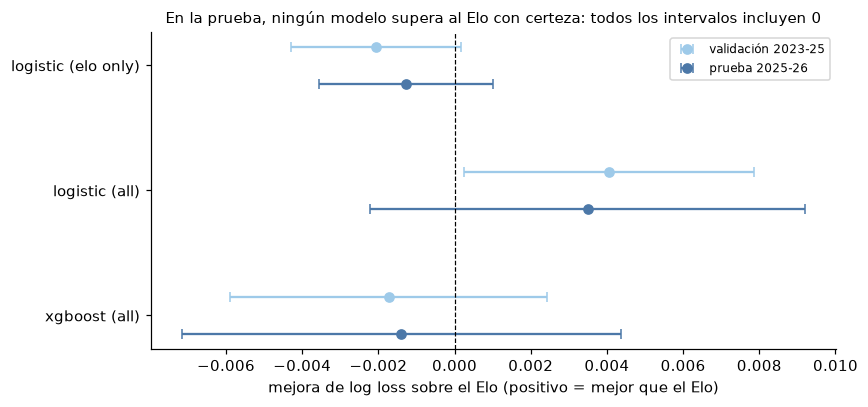

                       gain  ci_low  ci_high
logistic (elo only) -0.0013 -0.0036   0.0010
logistic (all)       0.0035 -0.0022   0.0092
xgboost (all)       -0.0014 -0.0072   0.0044


In [9]:
gv = sup.gain_vs_elo_validation.drop(index="home rate")
gt = sup.gain_vs_elo_test.drop(index="home rate")
n_clear = int(((gt["ci_low"] > 0) | (gt["ci_high"] < 0)).sum())

fig, ax = plt.subplots(figsize=(8, 3.8))
for offset, (label, frame, color) in zip(
    (-0.15, 0.15),
    (("validación 2023-25", gv, "#9ECAE9"), ("prueba 2025-26", gt, "#4C78A8")),
    strict=True,
):
    y = np.arange(len(frame)) + offset
    ax.errorbar(
        frame["gain"],
        y,
        xerr=[frame["gain"] - frame["ci_low"], frame["ci_high"] - frame["gain"]],
        fmt="o",
        color=color,
        capsize=3,
        label=label,
    )
ax.axvline(0, color="k", lw=0.8, ls="--")
ax.set_yticks(np.arange(len(gt)))
ax.set_yticklabels(gt.index)
ax.invert_yaxis()
ax.set_xlabel("mejora de log loss sobre el Elo (positivo = mejor que el Elo)")
title = (
    "En la prueba, ningún modelo supera al Elo con certeza: todos los intervalos incluyen 0"
    if n_clear == 0
    else f"En la prueba, {n_clear} modelo(s) superan al Elo con intervalo que excluye 0"
)
ax.set_title(title, fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(gt.round(4).to_string())

**Lectura honesta:**
- La logística con forma y descanso es la única con ganancia positiva en **validación y prueba** (≈ +0.004 y +0.0035). En validación el intervalo apenas excluye 0 (+0.0002 a +0.0079); en la prueba lo incluye. Señal consistente y pequeña, no una victoria clara. Probé 3 modelos en 2 etapas sin corregir por comparaciones múltiples, así que un intervalo que "apenas" excluye 0 no basta.
- La logística con solo la diferencia de Elo es el Elo recalibrado y no lo mejora: confirma que el Elo ya estaba bien calibrado.
- XGBoost no supera ni a la logística ni al Elo. Con 5 variables casi lineales y mucho ruido, los árboles agregan varianza, no señal.
- La diferencia de acierto entre modelos (68.1 % vs 68.5 %) son ~5 partidos de 1225: no significa nada.

### ¿Qué usa cada modelo?

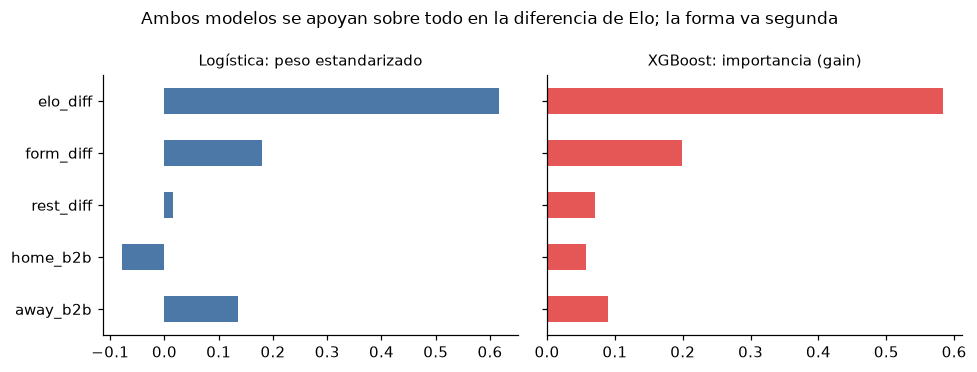

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
sup.logistic_coefficients.plot.barh(ax=axes[0], color="#4C78A8")
axes[0].set_title("Logística: peso estandarizado", fontsize=10)
sup.xgb_importance.plot.barh(ax=axes[1], color="#E45756")
axes[1].set_title("XGBoost: importancia (gain)", fontsize=10)
axes[0].invert_yaxis()
fig.suptitle(
    "Ambos modelos se apoyan sobre todo en la diferencia de Elo; la forma va segunda", fontsize=11
)
plt.tight_layout()
plt.show()

**Cuidado al interpretar:** `rest_diff`, `home_b2b` y `away_b2b` están correlacionadas entre sí (la diferencia de descanso contiene a los back-to-back), así que sus pesos individuales no se leen por separado. El signo de `away_b2b` (+) y `home_b2b` (-) sí es el esperado: un visitante cansado ayuda al local y viceversa.

## 8. Conclusiones del módulo
- El Elo supera claramente a los dos baselines en log loss y Brier, y sus probabilidades son razonablemente calibradas.
- La ventaja de local cayó; usar H=100 de memoria habría costado log loss.
- Forma y descanso aportan, a lo sumo, ~0.003-0.004 de log loss sobre el Elo: consistente en signo, estadísticamente borderline. XGBoost no justificó su complejidad.
- Lo que probablemente falta no es un modelo mejor sino **información**: lesiones, quién juega y descansos de estrellas no están en estas variables.
- El ajuste de H tocó el borde de la rejilla: hay que ampliarlo (solo con validación).

## 9. Ejercicios (hazlos tú)
1. Amplía la rejilla a `home_advantages=[0, 10, 20, 30, 40, 50]` y `ks=[16, 20, 24, 28]`, **solo mirando validación**. Antes de correr, escribe tu predicción de qué H gana y cuánto mejora el log loss de validación. Mirar 2025-26 después es una "segunda mirada", no una prueba limpia.
2. Añade una variable nueva en `team_form.py` (por ejemplo, partidos jugados en los últimos 7 días, o % de victorias en los últimos 10) y mide su ganancia contra el Elo **con intervalo**. Antes de correr, predice el signo y si el intervalo excluirá 0. Recuerda desplazar un partido hacia atrás y añadir un test de fuga.

> Mis predicciones: _(escríbelas aquí antes de correr)_